In [1]:
%% Homework 7
% Due 19 Nov 2026
% late :(
% Ely J, Dawson

Starting MATLAB ...
Executing ...

In [2]:
%% 1. Revisiting normalization and Parseval.
% Since many are still having occasional spectral normalization issues, 
% please choose any real time series we have used in this course and 
% show that Parseval’s theorem is satisfied for i) 2 degrees of freedom
% (exactly) and ii) for ≈ 10−20 half-overlapped segments with a correctly normalized
% Hanning window (approximately: say a few percent).

In [3]:
dataDir = fullfile(getenv('HOME'), 'SIO221a_Github_code_2026', ...
    'homework', 'HW5_data');

files = {
    'DM134A', 'OS_T8S110W_DM134A-20150425_D_WIND_10min.nc';
    'DM183A', 'OS_T8S110W_DM183A-20160321_D_WIND_10min.nc';
    'DM231A', 'OS_T8S110W_DM231A-20170606_D_WIND_10min.nc'
};

wind = struct();

for k = 1:size(files, 1)
    deployment = files{k, 1};
    filePath = fullfile(dataDir, files{k, 2});

    info = ncinfo(filePath);
    names = {info.Variables.Name};
    fields = matlab.lang.makeUniqueStrings(matlab.lang.makeValidName(names));

    timeIndex = find(strcmpi(names, 'time'), 1);

    timeInfo = info.Variables(timeIndex);

    timeDimName = timeInfo.Dimensions(1).Name;
    time = ncread(filePath, timeInfo.Name);
    time = double(time(:));

    data = struct();
    for j = 1:numel(names)
        values = ncread(filePath, names{j});
        dimNames = {info.Variables(j).Dimensions.Name};
        timeDim = find(strcmp(dimNames, timeDimName), 1);

        if j ~= timeIndex && ~isempty(timeDim) && ...
                isfloat(values) && any(isnan(values(:)))
            values = fillmissing(values, 'linear', timeDim, ...
                'SamplePoints', time, 'EndValues', 'none');
        end

        data.(fields{j}) = values;
    end

    wind.(deployment).data = data;
    wind.(deployment).info = info;
end

% Show the loaded variable names for the first deployment.
fieldnames(wind.DM134A.data)

% Code taken from homework 5.

ans = 12×1 cell array
    {'TIME'     }
    {'HEIGHT'   }
    {'LATITUDE' }
    {'LONGITUDE'}
    {'WDIR'     }
    {'WDIR_QC'  }
    {'WDIR_DM'  }
    {'WSPD'     }
    {'WSPD_QC'  }
    {'WSPD_DM'  }
    {'UWND'     }
    {'VWND'     }

Using samples 1 through 47581 (47581 observations).
Time-domain variance:       1.662001775
Periodogram integral:       1.662001775
Relative difference:        2.88658e-13 %

Number of segments:         15
Mean-square Hann window:    0.375000
Welch integral:             1.686541372
Weighted segment variance:  1.686541372
Difference from full variance: 1.477 %


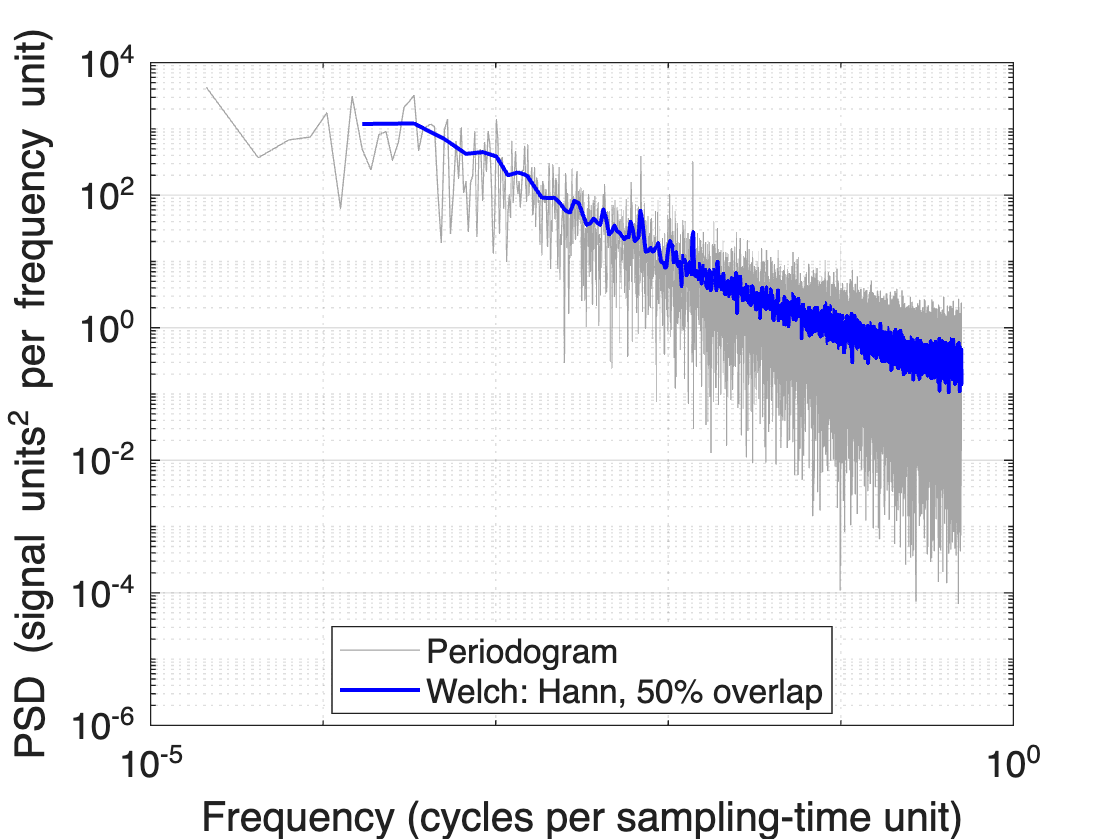

In [6]:
% Load wind speed
xraw = wind.DM134A.data.WSPD(:);
dt = 1;                    % Set to actual sampling interval
Fs = 1/dt;

% Find the longest continuous section of finite observations
valid = isfinite(xraw);
edges = diff([false; valid; false]);
first = find(edges == 1);
last  = find(edges == -1) - 1;

[~,j] = max(last-first+1);
x = xraw(first(j):last(j));

fprintf('Using samples %d through %d (%d observations).\n', ...
        first(j),last(j),length(x));

% Remove mean and calculate variance
x = x - mean(x);
N = length(x);
V = mean(x.^2);

%% (i) Full-record periodogram: nominally 2 DOF
[P1,f1] = periodogram(x,ones(N,1),N,Fs,'onesided');
df1 = Fs/N;
V1 = sum(P1)*df1;

fprintf('Time-domain variance:       %.10g\n',V);
fprintf('Periodogram integral:       %.10g\n',V1);
fprintf('Relative difference:        %.6g %%\n',100*(V1/V-1));

%% (ii) Approximately 15 segments with 50%% overlap
L = 2*floor(N/16);     
noverlap = L/2;
hop = L-noverlap;
w = hann(L,'periodic');  

[P2,f2] = pwelch(x,w,noverlap,L,Fs,'onesided');
df2 = Fs/L;
V2 = sum(P2)*df2;

% Exact time-domain quantity corresponding to the Welch integral
starts = 1:hop:(N-L+1);
K = length(starts);
Vweighted = zeros(K,1);

for j = 1:K
    segment = x(starts(j):starts(j)+L-1);
    Vweighted(j) = sum((w.*segment).^2)/sum(w.^2);
end

Vweighted = mean(Vweighted);

fprintf('\nNumber of segments:         %d\n',K);
fprintf('Mean-square Hann window:    %.6f\n',mean(w.^2));
fprintf('Welch integral:             %.10g\n',V2);
fprintf('Weighted segment variance:  %.10g\n',Vweighted);
fprintf('Difference from full variance: %.3f %%\n',100*(V2/V-1));

%% Plot both spectral estimates
figure
loglog(f1(2:end),P1(2:end),'Color',[0.65 0.65 0.65])
hold on
loglog(f2(2:end),P2(2:end),'b','LineWidth',1.5)
grid on
xlabel('Frequency (cycles per sampling-time unit)')
ylabel('PSD (signal units^2 per frequency unit)')
legend('Periodogram','Welch: Hann, 50% overlap','Location','best')

In [7]:
%% 2. Aliasing.
% The Surface Water and Ocean Topography (SWOT) satellite is due to launch soon. 
% It has two planned orbits. The initial calibration and validation will
% be carried out with a fast-sampling orbit, with an exact repeat of about a day,
% and the subsequent science mission will have about a 21-day repeat. Specific time
% periods are listed in the table below:
% 
% Orbit          period (days)
% Fast-sampling  0.99349
% Science        20.86455
% 
%% How will the following tidal frequencies be aliased by the satellite orbit? 
% See the table below with all frequencies listed. 
%
%% How long should the satellite operate in each orbit in order to separate these frequencies?
% See the table below with listed operational intervals for each orbit.
%
% Symbol     Name                             period (hours)
%  S1        Solar diurnal                    24.00
%  2N2       Second-order elliptical lunar    12.9054
%  N2        Larger elliptical lunar          12.6583
%  M2        Principal lunar                  12.4206
%  S2        Principal solar semidiurnal      12.00
%  K2        Declinational solar              11.9672

In [8]:
name = ["S1"; "2N2"; "N2"; "M2"; "S2"; "K2"];
periodHours = [24; 12.9054; 12.6583; 12.4206; 12; 11.9672];
f = 24 ./ periodHours;                  % cycles/day

orbitDays = [0.99349, 20.86455];
orbitName = ["Fast-sampling", "Science"];

for j = 1:length(orbitDays)
    fs = 1/orbitDays(j);

    % Fold into [0, fs/2] for a real-valued sampled signal
    fa = abs(f - round(f/fs)*fs);
    aliasDays = 1 ./ fa;

    fprintf('\n%s orbit\n', char(orbitName(j)));
    disp(table(name, f, fa, aliasDays, ...
        'VariableNames', ...
        {'Tide','Original_cpd','Alias_cpd','AliasPeriod_days'}));

    % Find the closest pair of aliased frequencies
    spacing = abs(fa - fa.');
    spacing(1:length(fa)+1:end) = Inf;   % Exclude diagonal

    [minimumSpacing, idx] = min(spacing(:));
    [a,b] = ind2sub(size(spacing),idx);
    requiredDays = 1/minimumSpacing;

    fprintf('Closest pair: %s and %s\n',char(name(a)),char(name(b)));
    fprintf('Required duration: %.1f days (%.2f years)\n', ...
        requiredDays,requiredDays/365.25);
end


Fast-sampling orbit
    Tide     Original_cpd    Alias_cpd    AliasPeriod_days
    _____    ____________    _________    ________________

    "S1"             1       0.0065527         152.61     
    "2N2"       1.8597         0.15342         6.5181     
    "N2"         1.896         0.11712         8.5385     
    "M2"        1.9323        0.080832         12.371     
    "S2"             2        0.013105         76.305     
    "K2"        2.0055       0.0076237         131.17     

Closest pair: K2 and S1
Required duration: 933.7 days (2.56 years)

Science orbit
    Tide     Original_cpd    Alias_cpd    AliasPeriod_days
    _____    ____________    _________    ________________

    "S1"             1       0.0064919         154.04     
    "2N2"       1.8597       0.0095125         105.12     
    "N2"         1.896        0.021138         47.308     
    "M2"        1.9323        0.015146         66.022     
    "S2"             2        0.012984         77.019     
    "K2" 

In [9]:
%% 3. Spectra of aliased signals.
% Use the same wind speed time series that you used
% for problem set #5, with the same gap filling and 60-day segments.
%% a Subsample the data set ever 40 data points (6.667 hours) and recompute the spectrum.
%
%% b Compare the resulting spectrum with the spectrum that you obtained for the
%% full data set by overlaying the subsampled plot over your earlier result.
%
%% c What is the resolution of the subsampled data set, and what is the Nyquist
%% frequency?
% The subsampled interval is 6.667 hours, 
% the frequency-bin spacing is (1/60=0.01667) cycles/day, and Nyquist is 1.8 cycles/day.
%
%% d Are the spectral peaks at the same frequencies as for the full record? Where
%% should the alias frequency of the semi-diurnal peak occur for the sub-sampled data?
% The diurnal frequency remains at 1 cycle/day. A semidiurnal signal at 2 cycles/day aliases 
% to 1.6 cycles/day, because (|2-3.6|=1.6). The low-frequency peaks occur at approximately the same 
% frequencies in the original (black) and subsampled (red) spectra, and the diurnal feature 
% remains near 1 cycle/day. At higher frequencies, the spectra differ because energy above the 
% subsampled Nyquist frequency of 1.8 cycles/day folds into the lower-frequency band.
% The red spectrum shows enhanced energy near the expected alias frequency of 1.6.
%
%% e How do the spectral energies compare? (To compare the subsampled spectra
%% to the full spectrum, you will need to make sure that your normalizations
%% are correct. Effectively you need a factor of 40 difference between the simple
%% un-normalized spectra.)
% The original and subsampled spectra have similar energy at low frequencies,
% where the curves nearly overlap. At higher frequencies below the new Nyquist limit, 
% the subsampled spectrum generally has more energy because power above 1.8 cycles/day 
% aliases into the lower-frequency band. 
% The semidiurnal peak at 2 cycles/day folds to 1.6 cycles/day.

DM134A: 10 segments used
DM183A: 13 segments used
DM231A: 9 segments used


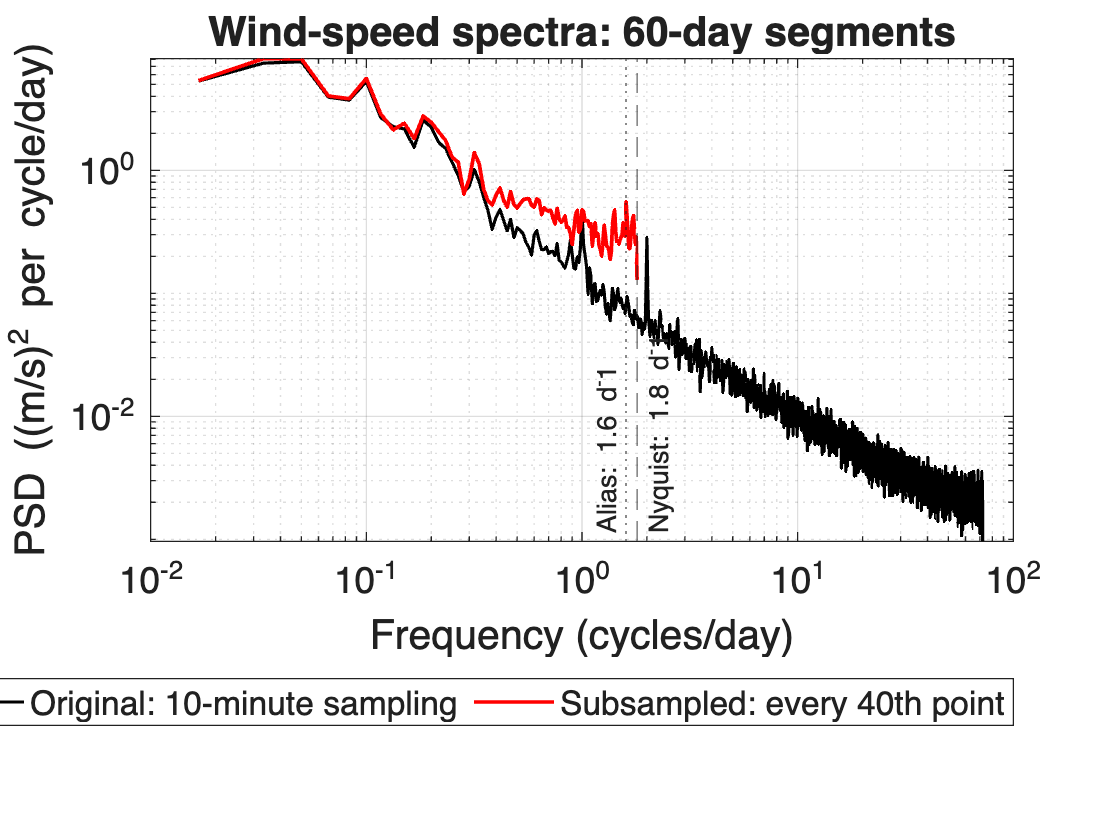


Total segments averaged: 32
Subsampled interval: 6.6667 hours
Frequency-bin spacing: 0.016667 cycles/day
Subsampled Nyquist: 1.800 cycles/day

Original spectral energy:    1.5972175 (m/s)^2
Subsampled spectral energy:  1.5795512 (m/s)^2
Relative energy difference:  -1.106 %

Original weighted time energy:   1.5972175
Subsampled weighted time energy: 1.5795512


In [15]:
%% 3. Spectra of aliased wind-speed signals

clearvars

%% Load the same three deployments used in HW5
dataDir = fullfile(getenv('HOME'), ...
    'SIO221a_Github_code_2026','homework','HW5_data');

files = {
    'DM134A','OS_T8S110W_DM134A-20150425_D_WIND_10min.nc';
    'DM183A','OS_T8S110W_DM183A-20160321_D_WIND_10min.nc';
    'DM231A','OS_T8S110W_DM231A-20170606_D_WIND_10min.nc'
};

dt = 600;                     
q = 40;
Fs = 1/dt;
FsSub = Fs/q;

N = 60*86400/dt;              
Ns = N/q;                     
hop = N/2;                

w = hann(N,'periodic');
ws = hann(Ns,'periodic');

f = (0:N/2)'*Fs/N;
fs = (0:Ns/2)'*FsSub/Ns;

sumP = zeros(size(f));
sumPs = zeros(size(fs));
timeEnergy = zeros(1,2);
K = 0;

for k = 1:size(files,1)
    filePath = fullfile(dataDir,files{k,2});

    % Locate time and wind-speed variables.
    info = ncinfo(filePath);
    names = {info.Variables.Name};
    it = find(strcmpi(names,'time'),1);
    ix = find(strcmpi(names,'WSPD'),1);

    t = double(ncread(filePath,names{it}));
    x = double(ncread(filePath,names{ix}));
    t = t(:);
    x = x(:);

    x = fillmissing(x,'linear','SamplePoints',t,'EndValues','none');

    starts = 1:hop:(numel(x)-N+1);
    used = 0;

    for s = starts
        idx = s:s+N-1;
        y = x(idx);

        % Time is in days in these files.
        regular = all(abs(diff(t(idx))*86400-dt) < 0.1);

        if ~regular || any(~isfinite(y))
            continue
        end

        % Subsample BEFORE detrending; no anti-alias filter.
        ys = y(1:q:end);

        % Match HW5: linearly detrend each segment, then Hann taper.
        y = detrend(y,1);
        ys = detrend(ys,1);

        X = fft(w.*y);
        Xs = fft(ws.*ys);

        % Correctly normalized one-sided PSDs, per Hz.
        p = abs(X(1:N/2+1)).^2/(Fs*sum(w.^2));
        ps = abs(Xs(1:Ns/2+1)).^2/(FsSub*sum(ws.^2));

        p(2:end-1) = 2*p(2:end-1);
        ps(2:end-1) = 2*ps(2:end-1);

        sumP = sumP+p;
        sumPs = sumPs+ps;

        % Exact time-domain counterparts of the spectral integrals.
        timeEnergy = timeEnergy + ...
            [sum((w.*y).^2)/sum(w.^2), ...
             sum((ws.*ys).^2)/sum(ws.^2)];

        K = K+1;
        used = used+1;
    end

    fprintf('%s: %d segments used\n',files{k,1},used);
end

P = sumP/K;
Ps = sumPs/K;
timeEnergy = timeEnergy/K;

%% a-b. Overlay original and subsampled spectra
% Convert frequency AND density to cycles/day units.
fDay = f*86400;
fsDay = fs*86400;
PDay = P/86400;
PsDay = Ps/86400;

figure
h1 = loglog(fDay(2:end),PDay(2:end),'k','LineWidth',1.2);
hold on
h2 = loglog(fsDay(2:end),PsDay(2:end),'r','LineWidth',1.4);

xline(1.8,'--','Nyquist: 1.8 d^-1', ...
    'LabelVerticalAlignment','bottom', ...
    'LabelHorizontalAlignment','right', ...
    'HandleVisibility','off');

xline(1.6,':','Alias: 1.6 d^-1', ...
    'LabelVerticalAlignment','bottom', ...
    'LabelHorizontalAlignment','left', ...
    'HandleVisibility','off');

grid on
xlabel('Frequency (cycles/day)')
ylabel('PSD ((m/s)^2 per cycle/day)')
title('Wind-speed spectra: 60-day segments')
legend([h1,h2],{'Original: 10-minute sampling', ...
    'Subsampled: every 40th point'}, ...
    'Location','southoutside','Orientation','horizontal');
%% c. Frequency-bin spacing and Nyquist frequency
fprintf('\nTotal segments averaged: %d\n',K);
fprintf('Subsampled interval: %.4f hours\n',q*dt/3600);
fprintf('Frequency-bin spacing: %.6f cycles/day\n',FsSub/Ns*86400);
fprintf('Subsampled Nyquist: %.3f cycles/day\n',FsSub/2*86400);

%% e. Integrated spectral energies and Parseval checks
E = sum(P)*(Fs/N);
Es = sum(Ps)*(FsSub/Ns);

fprintf('\nOriginal spectral energy:    %.8g (m/s)^2\n',E);
fprintf('Subsampled spectral energy:  %.8g (m/s)^2\n',Es);
fprintf('Relative energy difference:  %+.3f %%\n',100*(Es/E-1));

fprintf('\nOriginal weighted time energy:   %.8g\n',timeEnergy(1));
fprintf('Subsampled weighted time energy: %.8g\n',timeEnergy(2));